In [36]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [37]:
A = 0.2
r0 = 3.0
sigma = 1.0

num_points = 401
r_max = 10.0

T = 6.0
num_output_times = 101
dt0 = 0.0025

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [38]:
def gaussian_pulse(r, amplitude, r0, sigma):
    return amplitude * jnp.exp(-((r - r0) ** 2) / sigma**2)


def gaussian_pulse_dr(function):
    return jax.grad(function, argnums=0)


pulse_dr = gaussian_pulse_dr(gaussian_pulse)

In [39]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
        pulse_dr,
        in_axes=(0, None, None, None),
    )(r_aux, amplitude, r0, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [40]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = gaussian_pulse(
        r_physical, amplitude, r0, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(1.0)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [41]:
initial_state = make_initial_state(A)

Ham, Mom = get_constraints_diagnostic(
    initial_state,
    jnp.array([0.0]),
    grid,
    background,
    matter,
)

# Exclude the ghost cells and the last two physical points,
# where the outer boundary can affect the finite-difference stencil.
interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(jnp.abs(Ham[0, interior]))
mom_error = jnp.max(
    jnp.linalg.norm(Mom[0, interior], axis=-1)
)

print("All initial-state values finite:",
      bool(jnp.all(jnp.isfinite(initial_state))))
print("All psi values positive:",
      bool(jnp.all(solve_psi(r_physical, dr, A, r0, sigma) > 0)))
print("Largest interior Hamiltonian constraint:", float(ham_error))
print("Largest interior momentum constraint:", float(mom_error))

All initial-state values finite: True
All psi values positive: True
Largest interior Hamiltonian constraint: 4.82311575957872e-05
Largest interior momentum constraint: 0.0


In [42]:
def evolve(amplitude):
    y0 = make_initial_state(amplitude)

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter)

    save_times = jnp.linspace(0.0, T, num_output_times)

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(),
        t0=0.0,
        t1=T,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=dfx.SaveAt(ts=save_times),
        max_steps=2600,
    )

    return solution

Minimum innermost physical lapse: 0.21381929540331124


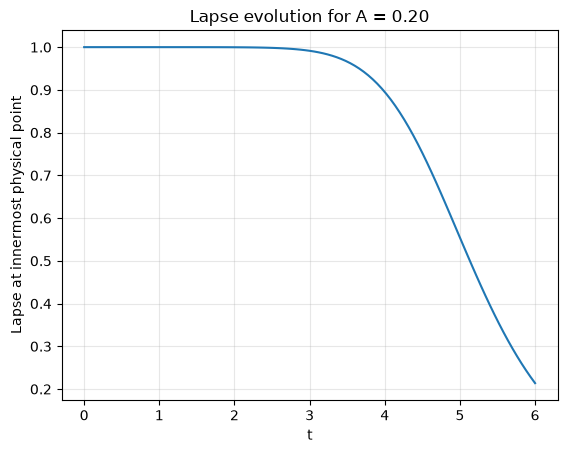

In [43]:
solution = evolve(A)

state_history = solution.ys.reshape(
    solution.ts.size,
    grid.NUM_VARS,
    grid.N,
)
lapse_history = state_history[:, idx_lapse, NUM_GHOSTS]

print("Minimum innermost physical lapse:",
      float(jnp.min(lapse_history)))

plt.plot(solution.ts, lapse_history)
plt.xlabel("t")
plt.ylabel("Lapse at innermost physical point")
plt.title(f"Lapse evolution for A = {A:.2f}")
plt.grid(alpha=0.3)
plt.show()

In [49]:
lapse_initial = state_history[0, idx_lapse]
lapse_final = state_history[-1, idx_lapse]

print("Maximum lapse change anywhere on grid:",
      float(jnp.max(jnp.abs(lapse_final - lapse_initial))))
print("Lapse change at innermost physical point:",
      float(lapse_final[NUM_GHOSTS] - lapse_initial[NUM_GHOSTS]))
print("Maximum change in the full state:",
      float(jnp.max(jnp.abs(solution.ys[-1] - solution.ys[0]))))

Maximum lapse change anywhere on grid: 0.7861807045966888
Lapse change at innermost physical point: -0.7861807045966888
Maximum change in the full state: 0.7861807045966888


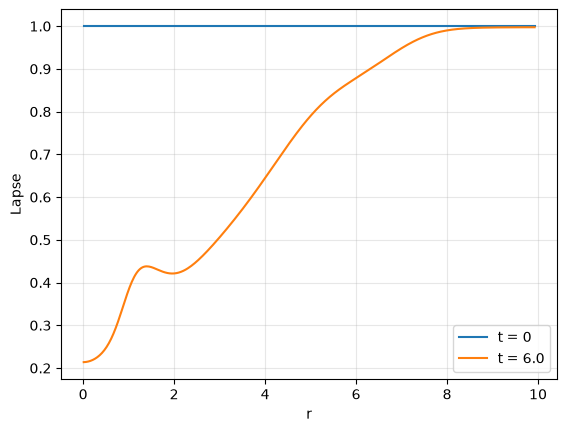

In [45]:
plt.plot(grid.r[physical], lapse_initial[physical], label="t = 0")
plt.plot(grid.r[physical], lapse_final[physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("Lapse")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Maximum scalar-field change: 0.21094002232512074


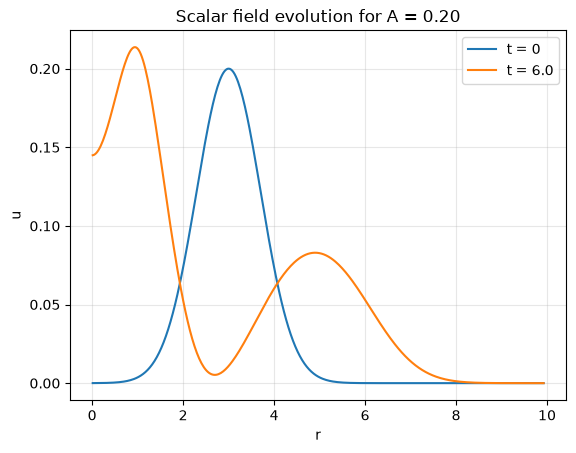

In [46]:
u_history = state_history[:, matter.idx_u, :]

print("Maximum scalar-field change:",
      float(jnp.max(jnp.abs(u_history[-1] - u_history[0]))))

plt.plot(grid.r[physical], u_history[0, physical], label="t = 0")
plt.plot(grid.r[physical], u_history[-1, physical], label=f"t = {T}")
plt.xlabel("r")
plt.ylabel("u")
plt.title(f"Scalar field evolution for A = {A:.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Check that constraints are satisfied

In [47]:
Ham_history, Mom_history = get_constraints_diagnostic(
    solution.ys,
    solution.ts,
    grid,
    background,
    matter,
)

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)
mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

print("Largest interior Hamiltonian constraint at t=0:",
      float(ham_error[0]))
print("Largest interior Hamiltonian constraint at t=6:",
      float(ham_error[-1]))
print("Largest interior momentum constraint at t=6:",
      float(mom_error[-1]))

Largest interior Hamiltonian constraint at t=0: 4.82311575957872e-05
Largest interior Hamiltonian constraint at t=6: 0.12692220908741314
Largest interior momentum constraint at t=6: 0.006432981803212324


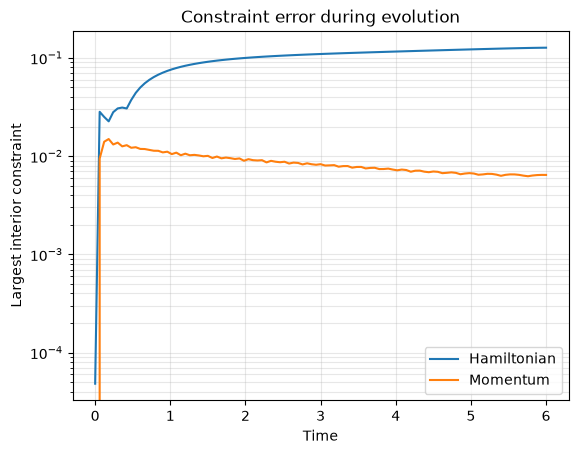

t=0.00: H=4.82312e-05, M=0
t=1.50: H=0.0912482, M=0.0100576
t=3.00: H=0.109476, M=0.00827426
t=4.50: H=0.118996, M=0.00697221
t=6.00: H=0.126922, M=0.00643298


In [50]:
import matplotlib.pyplot as plt

interior = slice(NUM_GHOSTS, -NUM_GHOSTS - 2)

ham_error = jnp.max(
    jnp.abs(Ham_history[:, interior]),
    axis=1,
)

mom_error = jnp.max(
    jnp.linalg.norm(Mom_history[:, interior, :], axis=-1),
    axis=1,
)

plt.semilogy(solution.ts, ham_error, label="Hamiltonian")
plt.semilogy(solution.ts, mom_error, label="Momentum")
plt.xlabel("Time")
plt.ylabel("Largest interior constraint")
plt.title("Constraint error during evolution")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

for i in [0, 25, 50, 75, 100]:
    print(
        f"t={float(solution.ts[i]):.2f}: "
        f"H={float(ham_error[i]):.6g}, "
        f"M={float(mom_error[i]):.6g}"
    )

In [51]:
# Largest Hamiltonian error at the final time
ham_final = jnp.abs(Ham_history[-1, interior])
ham_local_index = int(jnp.argmax(ham_final))
ham_index = ham_local_index + NUM_GHOSTS

print(
    "Hamiltonian maximum:",
    float(ham_final[ham_local_index]),
    "at r =",
    float(grid.r[ham_index]),
)

# Largest momentum error at the final time
mom_final = jnp.linalg.norm(Mom_history[-1, interior, :], axis=-1)
mom_local_index = int(jnp.argmax(mom_final))
mom_index = mom_local_index + NUM_GHOSTS

print(
    "Momentum maximum:",
    float(mom_final[mom_local_index]),
    "at r =",
    float(grid.r[mom_index]),
)

Hamiltonian maximum: 0.12692220908741314 at r = 9.874213836477987
Momentum maximum: 0.006432981803212324 at r = 6.553459119496854


In [52]:
bulk = (grid.r > 0.0) & (grid.r < 9.0)

ham_bulk = jnp.abs(Ham_history[-1, bulk])
ham_i = int(jnp.argmax(ham_bulk))
ham_r = grid.r[bulk][ham_i]

mom_bulk = jnp.linalg.norm(Mom_history[-1, bulk, :], axis=-1)
mom_i = int(jnp.argmax(mom_bulk))
mom_r = grid.r[bulk][mom_i]

print("Hamiltonian maximum for r < 9:", float(ham_bulk[ham_i]), "at r =", float(ham_r))
print("Momentum maximum for r < 9:", float(mom_bulk[mom_i]), "at r =", float(mom_r))

Hamiltonian maximum for r < 9: 0.0003344516860317964 at r = 7.283018867924527
Momentum maximum for r < 9: 0.006432981803212324 at r = 6.553459119496854


In [53]:
r_checks = [6.55, 7.28]
time_indices = [0, 1, 2, 5, 10, 25, 50, 75, 100]

for r_check in r_checks:
    i = int(jnp.argmin(jnp.abs(grid.r - r_check)))
    print(f"\nNearest grid point to r={r_check}: r={float(grid.r[i]):.4f}")

    for k in time_indices:
        momentum = jnp.linalg.norm(Mom_history[k, i, :])
        print(
            f"t={float(solution.ts[k]):.2f}: "
            f"H={float(jnp.abs(Ham_history[k, i])):.6g}, "
            f"M={float(momentum):.6g}"
        )


Nearest grid point to r=6.55: r=6.5535
t=0.00: H=1.68867e-12, M=0
t=0.06: H=1.90273e-11, M=1.43561e-14
t=0.12: H=2.92837e-12, M=1.1766e-15
t=0.30: H=4.72538e-12, M=3.03961e-13
t=0.60: H=3.86203e-12, M=2.20749e-12
t=1.50: H=6.21498e-11, M=2.18001e-10
t=3.00: H=2.46752e-09, M=5.27273e-08
t=4.50: H=3.44274e-08, M=5.22099e-07
t=6.00: H=7.15958e-05, M=0.00643298

Nearest grid point to r=7.28: r=7.2830
t=0.00: H=8.98873e-13, M=0
t=0.06: H=4.54634e-12, M=1.45243e-14
t=0.12: H=2.24489e-12, M=8.88001e-15
t=0.30: H=7.0563e-12, M=4.70269e-14
t=0.60: H=1.6693e-11, M=8.33618e-14
t=1.50: H=1.27255e-11, M=4.29068e-13
t=3.00: H=2.40446e-09, M=1.09262e-09
t=4.50: H=6.82306e-05, M=0.00568737
t=6.00: H=0.000334452, M=7.5703e-06


In [55]:
physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
idx_K = 4
idx_lapse = 11
for k in [0, 25, 50, 75, 100]:
    lapse_min = jnp.min(state_history[k, idx_lapse, physical])
    K_max = jnp.max(jnp.abs(state_history[k, idx_K, physical]))

    print(
        f"t={float(solution.ts[k]):.2f}: "
        f"minimum lapse={float(lapse_min):.6g}, "
        f"maximum |K|={float(K_max):.6g}, "
        f"H error={float(ham_error[k]):.6g}, "
        f"M error={float(mom_error[k]):.6g}"
    )

t=0.00: minimum lapse=1, maximum |K|=0, H error=4.82312e-05, M error=0
t=1.50: minimum lapse=0.96917, maximum |K|=0.0340195, H error=0.0912482, M error=0.0100576
t=3.00: minimum lapse=0.811783, maximum |K|=0.0903467, H error=0.109476, M error=0.00827426
t=4.50: minimum lapse=0.621602, maximum |K|=0.242694, H error=0.118996, M error=0.00697221
t=6.00: minimum lapse=0.213819, maximum |K|=0.551774, H error=0.126922, M error=0.00643298
